# Projet F8 – Peut-on battre la marche aléatoire ? Action Attijariwafa Bank (ATW)


## 1. Bibliothèques et paramètres

In [12]:
import os, re, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from scipy.stats import binomtest
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             balanced_accuracy_score, confusion_matrix, ConfusionMatrixDisplay)
warnings.filterwarnings("ignore")

FICHIER_CSV = "Attijariwafa_Bank_Stock_Price_History.csv"
DOSSIER_FIG, DOSSIER_RES = "figures", "resultats"
GRAINE, COUT = 42, 0.001            # graine aléatoire ; coût de transaction (0,1 % par changement)
os.makedirs(DOSSIER_FIG, exist_ok=True)
os.makedirs(DOSSIER_RES, exist_ok=True)
np.random.seed(GRAINE)

BLEU, ROUGE, VERT, GRIS, ORANGE = "#1F3A5F", "#B23A48", "#2E7D32", "#7F8C8D", "#E08E0B"
plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 300, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "font.size": 11, "axes.titlesize": 13, "axes.titleweight": "bold"})

def sauver(nom):
    """Enregistre la figure courante en PNG (300 dpi) dans figures/ puis l'affiche."""
    plt.tight_layout()
    plt.savefig(os.path.join(DOSSIER_FIG, nom), dpi=300, bbox_inches="tight")
    plt.show()

def axe_dates(ax):
    ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 7]))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%m/%Y"))

## 2. Fonctions de lecture robustes (formats de nombres, dates, volumes, pourcentages)

In [13]:
def _nombre(x):
    """'1,234.50' / '1.234,50' / '694,60' / '694.60' -> float ; sinon NaN."""
    s = str(x).strip().replace("\u202f", "").replace(" ", "")
    if "," in s and "." in s:
        s = s.replace(".", "").replace(",", ".") if s.rfind(",") > s.rfind(".") else s.replace(",", "")
    elif "," in s:
        s = s.replace(",", "") if re.fullmatch(r"-?\d{1,3}(,\d{3})+", s) else s.replace(",", ".")
    try:
        return float(s)
    except ValueError:
        return np.nan

def _volume(x):
    """'34.19K' -> 34190 ; '1.43M' -> 1 430 000 ; '-' -> NaN."""
    s = str(x).strip().upper()
    mult = {"K": 1e3, "M": 1e6, "B": 1e9}
    if s and s[-1] in mult:
        return _nombre(s[:-1]) * mult[s[-1]]
    return _nombre(s)

def _pct(x):
    """'3.67%' -> 3.67 (en points de pourcentage)."""
    return _nombre(str(x).replace("%", ""))

def _dates(col):
    """Détecte automatiquement JJ/MM/AAAA ou MM/JJ/AAAA (si un 1er nombre dépasse 12 -> jour d'abord)."""
    s = col.astype(str).str.strip()
    premier = pd.to_numeric(s.str.extract(r"^(\d{1,2})[/\-.]")[0], errors="coerce")
    return pd.to_datetime(s, dayfirst=bool((premier > 12).any()), errors="coerce")

def _col(df, noms):
    """Retourne la première colonne dont le nom (nettoyé) figure dans la liste."""
    return next((c for c in df.columns if c in noms), None)

def lire_csv(chemin):
    df = pd.read_csv(chemin, encoding="utf-8-sig")
    df.columns = [c.strip().lower().replace("\ufeff", "") for c in df.columns]
    c = {"date": _col(df, ("date", "séance", "seance")),
         "close": _col(df, ("price", "close", "clôture", "cloture", "dernier", "cours")),
         "open": _col(df, ("open", "ouverture")), "high": _col(df, ("high", "plus haut")),
         "low": _col(df, ("low", "plus bas")), "vol": _col(df, ("vol.", "vol", "volume")),
         "chg": _col(df, ("change %", "variation %", "var %"))}
    out = pd.DataFrame({"date": _dates(df[c["date"]]), "close": df[c["close"]].map(_nombre)})
    for k in ("open", "high", "low"):
        out[k] = df[c[k]].map(_nombre) if c[k] else np.nan
    out["volume"] = df[c["vol"]].map(_volume) if c["vol"] else np.nan
    out["change_pct"] = df[c["chg"]].map(_pct) if c["chg"] else np.nan
    return out, df

## 3. Chargement et contrôle de qualité

In [14]:
for _dossier in ("", "data", "/content", "/content/data"):      #
    if os.path.exists(os.path.join(_dossier, FICHIER_CSV)):
        FICHIER_CSV = os.path.join(_dossier, FICHIER_CSV)
        break
if not os.path.exists(FICHIER_CSV):
    try:
        from google.colab import files
        up = files.upload()
        FICHIER_CSV = list(up.keys())[0]
    except ImportError:
        raise FileNotFoundError(f"Placez {FICHIER_CSV} dans le dossier du notebook.")

brut, brut_txt = lire_csv(FICHIER_CSV)
print("Colonnes d'origine :", list(brut_txt.columns), "| Variables :", brut_txt.shape[1])
print("Types d'origine :\n", brut_txt.dtypes.to_string(), "\n")

controle = {
    "Observations lues": len(brut),
    "Variables d'origine": brut_txt.shape[1],
    "Dates illisibles": int(brut["date"].isna().sum()),
    "Prix manquants": int(brut["close"].isna().sum()),
    "Doublons de date": int(brut["date"].duplicated().sum()),
    "Prix négatifs ou nuls": int((brut["close"] <= 0).sum()),
}
df = (brut.dropna(subset=["date", "close"]).drop_duplicates("date")
          .sort_values("date").reset_index(drop=True))          # tri chronologique
df = df[df["close"] > 0].reset_index(drop=True)
ecarts = df["date"].diff().dt.days.dropna()
controle["Plus long intervalle entre deux séances (jours)"] = int(ecarts.max())
controle["Clôture hors de [Low, High]"] = int(((df["close"] > df["high"]) | (df["close"] < df["low"])).sum())
df["ret"] = df["close"].pct_change()                           # rendement simple clôture à clôture
controle["Écart max |Change % fourni - rendement recalculé| (points de %)"] = round(
    float((df["ret"] * 100 - df["change_pct"]).abs().max()), 4)
controle["Observations retenues"] = len(df)
print(pd.Series(controle).to_string())
print("Période :", df["date"].min().date(), "->", df["date"].max().date())
print("Intervalles les plus longs :", ecarts.sort_values(ascending=False).head(3).astype(int).tolist(), "jours")
pd.Series(controle).to_csv(f"{DOSSIER_RES}/controle_qualite.csv", header=["valeur"])

Colonnes d'origine : ['date', 'price', 'open', 'high', 'low', 'vol.', 'change %'] | Variables : 7
Types d'origine :
 date         object
price       float64
open        float64
high        float64
low         float64
vol.         object
change %     object 

Observations lues                                                  1197.000
Variables d'origine                                                   7.000
Dates illisibles                                                      0.000
Prix manquants                                                        0.000
Doublons de date                                                      0.000
Prix négatifs ou nuls                                                 0.000
Plus long intervalle entre deux séances (jours)                       6.000
Clôture hors de [Low, High]                                           1.000
Écart max |Change % fourni - rendement recalculé| (points de %)       0.005
Observations retenues                                    

## 4. Statistiques descriptives

In [15]:
desc = df[["close", "open", "high", "low", "volume", "change_pct"]].describe().T
print(desc.round(2).to_string())
desc.round(4).to_csv(f"{DOSSIER_RES}/stats_descriptives.csv")
print(f"\nRendement moyen {df['ret'].mean()*100:.4f} % | écart-type {df['ret'].std()*100:.4f} % | "
      f"asymétrie {df['ret'].skew():.3f} | kurtosis excès {df['ret'].kurt():.3f}")
print(f"Part de hausses {(df['ret']>0).mean()*100:.1f} % | baisses {(df['ret']<0).mean()*100:.1f} % | nuls {(df['ret']==0).mean()*100:.1f} %")

             count      mean       std     min       25%      50%       75%         max
close       1197.0    553.29    124.51  355.05    446.00    512.0    680.20      789.90
open        1197.0    552.53    124.47  360.00    445.50    510.0    680.00      790.00
high        1197.0    557.23    125.87  360.00    449.95    514.9    686.00      804.00
low         1197.0    549.18    123.36  355.05    443.05    508.3    676.00      781.00
volume      1197.0  50956.30  80834.65   10.00  14540.00  29300.0  57270.00  1430000.00
change_pct  1197.0      0.04      1.21   -5.17     -0.54      0.0      0.52        5.99

Rendement moyen 0.0363 % | écart-type 1.2062 % | asymétrie 0.194 | kurtosis excès 3.848
Part de hausses 45.5 % | baisses 44.8 % | nuls 9.6 %


## 5. Visualisations descriptives

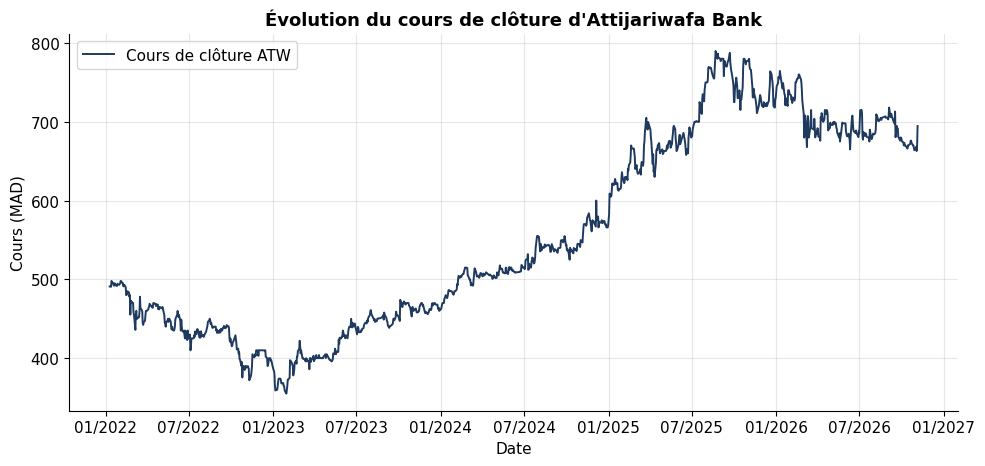

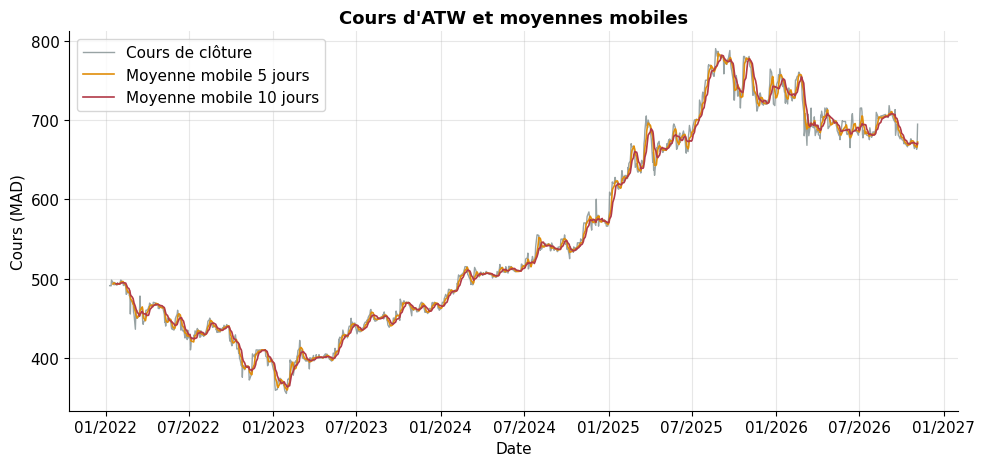

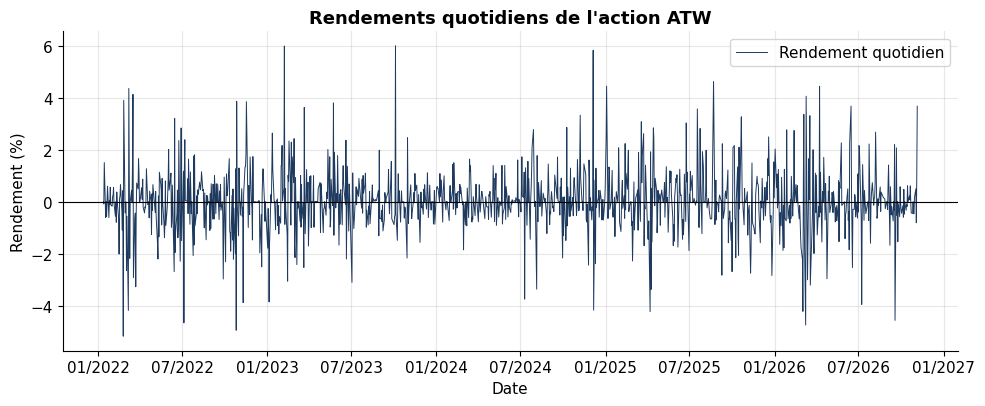

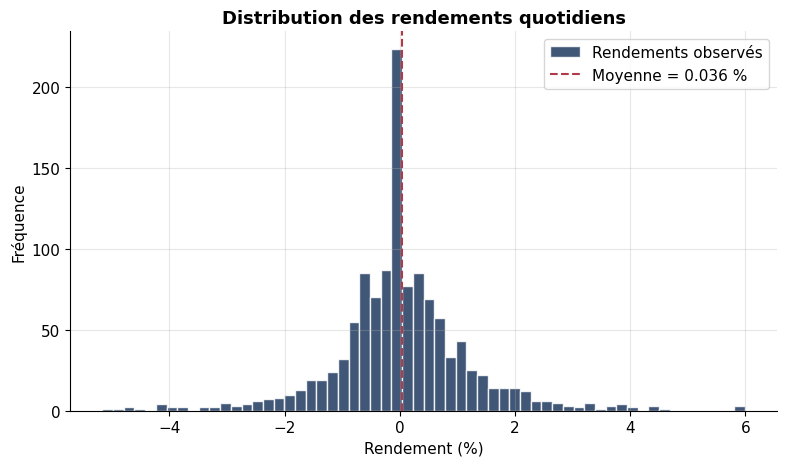

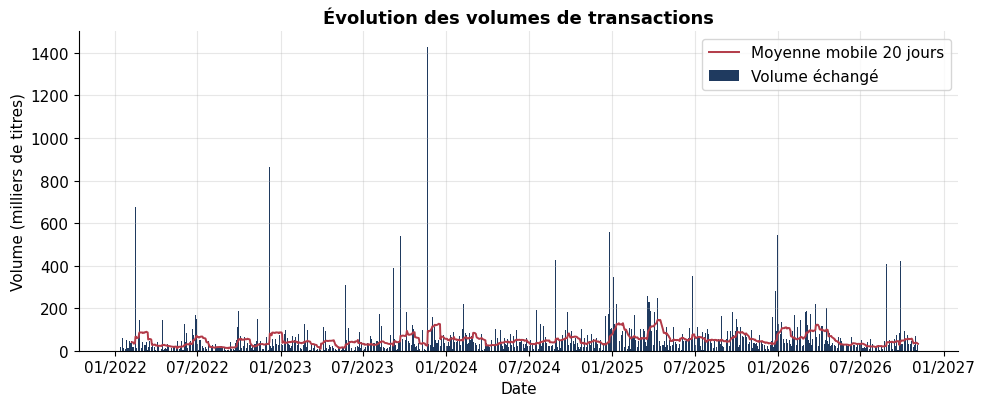

In [16]:
fig, ax = plt.subplots(figsize=(10, 4.8))
ax.plot(df["date"], df["close"], color=BLEU, lw=1.4, label="Cours de clôture ATW")
ax.set(title="Évolution du cours de clôture d'Attijariwafa Bank", xlabel="Date", ylabel="Cours (MAD)")
axe_dates(ax); ax.legend(); sauver("fig01_cours_cloture.png")

fig, ax = plt.subplots(figsize=(10, 4.8))
ax.plot(df["date"], df["close"], color=GRIS, lw=1, alpha=0.8, label="Cours de clôture")
ax.plot(df["date"], df["close"].rolling(5).mean(), color=ORANGE, lw=1.2, label="Moyenne mobile 5 jours")
ax.plot(df["date"], df["close"].rolling(10).mean(), color=ROUGE, lw=1.2, label="Moyenne mobile 10 jours")
ax.set(title="Cours d'ATW et moyennes mobiles", xlabel="Date", ylabel="Cours (MAD)")
axe_dates(ax); ax.legend(); sauver("fig02_moyennes_mobiles.png")

fig, ax = plt.subplots(figsize=(10, 4.2))
ax.plot(df["date"], df["ret"] * 100, color=BLEU, lw=0.7, label="Rendement quotidien")
ax.axhline(0, color="black", lw=0.8)
ax.set(title="Rendements quotidiens de l'action ATW", xlabel="Date", ylabel="Rendement (%)")
axe_dates(ax); ax.legend(); sauver("fig03_rendements_quotidiens.png")

r = df["ret"].dropna() * 100
fig, ax = plt.subplots(figsize=(8, 4.8))
ax.hist(r, bins=60, color=BLEU, alpha=0.85, edgecolor="white", label="Rendements observés")
ax.axvline(r.mean(), color=ROUGE, ls="--", label=f"Moyenne = {r.mean():.3f} %")
ax.set(title="Distribution des rendements quotidiens", xlabel="Rendement (%)", ylabel="Fréquence")
ax.legend(); sauver("fig04_distribution_rendements.png")

fig, ax = plt.subplots(figsize=(10, 4.2))
ax.bar(df["date"], df["volume"] / 1e3, width=1.5, color=BLEU, label="Volume échangé")
ax.plot(df["date"], df["volume"].rolling(20).mean() / 1e3, color=ROUGE, lw=1.4, label="Moyenne mobile 20 jours")
ax.set(title="Évolution des volumes de transactions", xlabel="Date", ylabel="Volume (milliers de titres)")
axe_dates(ax); ax.legend(); sauver("fig05_volumes.png")

## 6. Variables explicatives et cible (aucune information future : tout est calculé avec des données <= t)

Observations : 1197 -> 1186 après suppression des lignes inexploitables
Part de hausses (cible = 1) : 45.70 % | rendements nuls classés 0 : 113


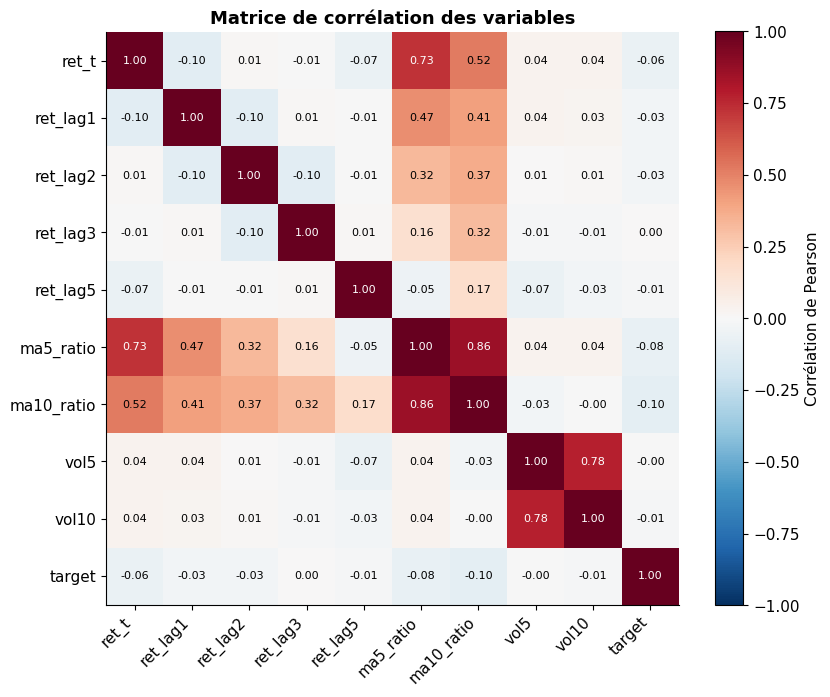

In [17]:
feat = pd.DataFrame({"date": df["date"], "ret_t": df["ret"]})
for k in (1, 2, 3, 5):                                         # rendements retardés J-1, J-2, J-3, J-5
    feat[f"ret_lag{k}"] = df["ret"].shift(k)
feat["ma5_ratio"] = df["close"] / df["close"].rolling(5).mean() - 1      # écart relatif à la MM 5 jours
feat["ma10_ratio"] = df["close"] / df["close"].rolling(10).mean() - 1    # écart relatif à la MM 10 jours
feat["vol5"] = df["ret"].rolling(5).std()
feat["vol10"] = df["ret"].rolling(10).std()
feat["ret_next"] = df["ret"].shift(-1)                          # rendement du lendemain (jamais une variable explicative)
feat["target"] = (feat["ret_next"] > 0).astype(int)             # 1 = hausse ; 0 = baisse ou stabilité
VARIABLES = ["ret_t", "ret_lag1", "ret_lag2", "ret_lag3", "ret_lag5", "ma5_ratio", "ma10_ratio", "vol5", "vol10"]
n_avant = len(feat)
feat = feat.dropna(subset=VARIABLES + ["ret_next"]).reset_index(drop=True)
print(f"Observations : {n_avant} -> {len(feat)} après suppression des lignes inexploitables")
print(f"Part de hausses (cible = 1) : {feat['target'].mean()*100:.2f} % | rendements nuls classés 0 : {(feat['ret_next']==0).sum()}")

corr = feat[VARIABLES + ["target"]].corr()
fig, ax = plt.subplots(figsize=(8.5, 7))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr))); ax.set_yticks(range(len(corr)))
ax.set_xticklabels(corr.columns, rotation=45, ha="right"); ax.set_yticklabels(corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8,
                color="white" if abs(corr.iloc[i, j]) > 0.6 else "black")
ax.grid(False); plt.colorbar(im, ax=ax, label="Corrélation de Pearson")
ax.set_title("Matrice de corrélation des variables"); sauver("fig06_matrice_correlation.png")
corr.round(3).to_csv(f"{DOSSIER_RES}/correlation.csv")

## 7. Découpage chronologique 80 % / 20 %

In [18]:
n = len(feat); n_train = int(n * 0.8)
train = feat.iloc[:n_train - 1].copy()      # on retire la dernière ligne : sa cible = 1er jour du test
test = feat.iloc[n_train:].copy()
X_tr, y_tr, X_te, y_te = train[VARIABLES], train["target"], test[VARIABLES], test["target"]
print(f"Entraînement : {len(train)} obs. ({train['date'].min().date()} -> {train['date'].max().date()}) | hausses {y_tr.mean()*100:.1f} %")
print(f"Test         : {len(test)} obs. ({test['date'].min().date()} -> {test['date'].max().date()}) | hausses {y_te.mean()*100:.1f} %")

Entraînement : 947 obs. (2022-01-25 -> 2025-11-12) | hausses 46.9 %
Test         : 238 obs. (2025-11-14 -> 2026-11-04) | hausses 41.2 %


## 8. Entraînement (standardisation dans le Pipeline = ajustée sur l'entraînement uniquement)

In [19]:
cv = TimeSeriesSplit(n_splits=5)            # validation croisée temporelle, sur l'entraînement seulement
base = DummyClassifier(strategy="most_frequent").fit(X_tr, y_tr)
print("Baseline : prédit toujours la classe", int(base.predict(X_te)[0]), "(0 = baisse/stabilité, 1 = hausse)")

gs_lr = GridSearchCV(Pipeline([("sc", StandardScaler()), ("clf", LogisticRegression(max_iter=1000, random_state=GRAINE))]),
                     {"clf__C": [0.01, 0.1, 1, 10]}, cv=cv, scoring="balanced_accuracy").fit(X_tr, y_tr)
logit = gs_lr.best_estimator_
print("Régression logistique – meilleur C :", gs_lr.best_params_, "| score CV :", round(gs_lr.best_score_, 4))

gs_rf = GridSearchCV(RandomForestClassifier(n_estimators=300, random_state=GRAINE, n_jobs=-1),
                     {"max_depth": [3, 5, 8], "min_samples_leaf": [10, 20, 40]},
                     cv=cv, scoring="balanced_accuracy", n_jobs=-1).fit(X_tr, y_tr)
rf = gs_rf.best_estimator_
print("Forêt aléatoire – meilleurs paramètres :", gs_rf.best_params_, "| score CV :", round(gs_rf.best_score_, 4))

coefs = pd.Series(logit.named_steps["clf"].coef_[0], index=VARIABLES).sort_values()
imp = pd.Series(rf.feature_importances_, index=VARIABLES).sort_values()
print("\nCoefficients (variables standardisées) :\n", coefs.round(4).to_string())
coefs.round(4).to_csv(f"{DOSSIER_RES}/coefficients_logit.csv")
imp.sort_values(ascending=False).round(4).to_csv(f"{DOSSIER_RES}/importance_rf.csv")

Baseline : prédit toujours la classe 0 (0 = baisse/stabilité, 1 = hausse)
Régression logistique – meilleur C : {'clf__C': 10} | score CV : 0.5073
Forêt aléatoire – meilleurs paramètres : {'max_depth': 3, 'min_samples_leaf': 20} | score CV : 0.5175

Coefficients (variables standardisées) :
 ma10_ratio   -0.4291
vol5         -0.0438
ret_t         0.0129
vol10         0.0172
ret_lag5      0.0645
ret_lag1      0.0757
ret_lag3      0.1167
ret_lag2      0.1220
ma5_ratio     0.1270


## 9. Évaluation et comparaison (tests indicatifs : binomial et permutation)

                        Accuracy  Precision  Recall      F1  Balanced Acc.  % prédit hausse  p-val vs baseline  p-val vs 50%  p-val permutation (BA)
Modèle                                                                                                                                              
Baseline (majoritaire)    0.5882     0.0000  0.0000  0.0000         0.5000           0.0000             0.5278        0.0039                     NaN
Régression logistique     0.5630     0.4625  0.3776  0.4157         0.5352           0.3361             0.8043        0.0300                  0.1616
Random Forest             0.5966     0.5192  0.2755  0.3600         0.5485           0.2185             0.4232        0.0017                  0.0514


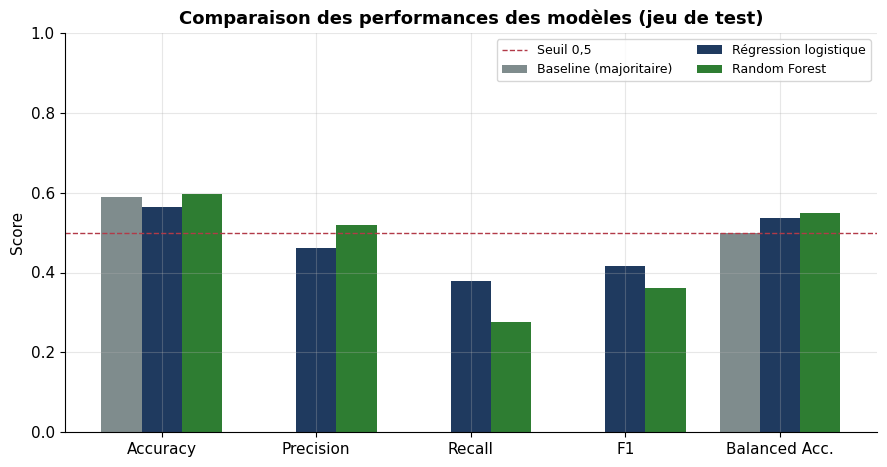

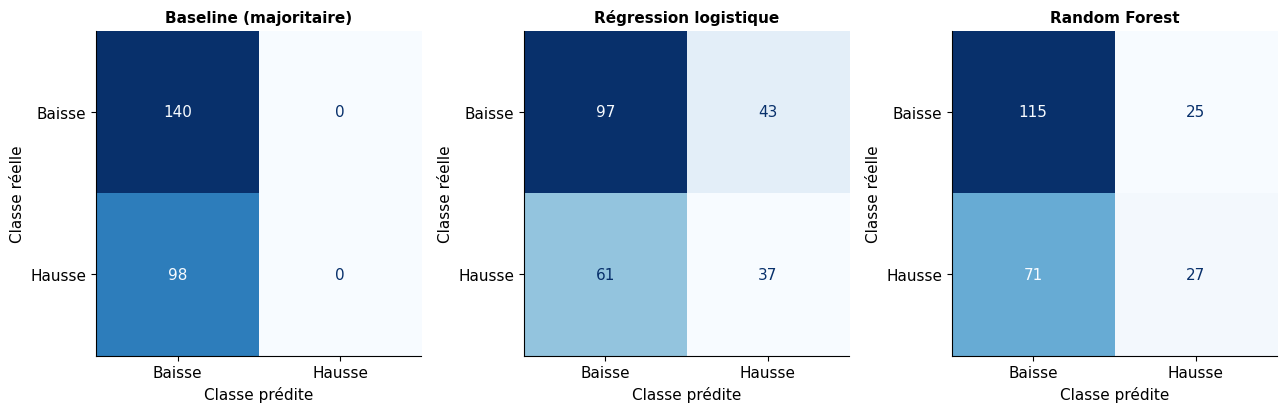

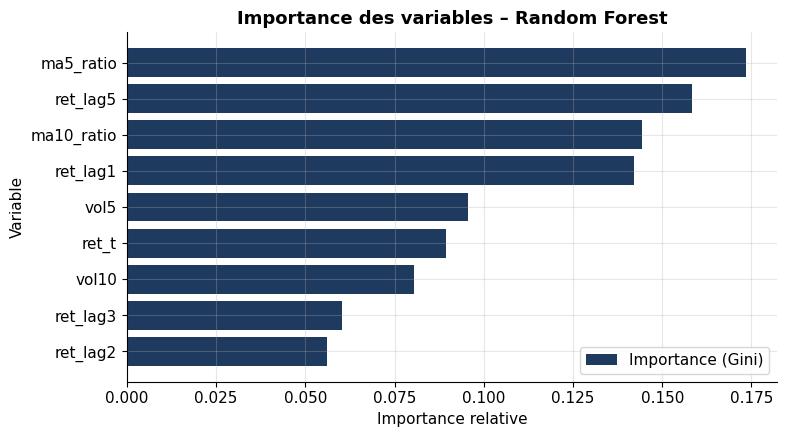

In [20]:
modeles = {"Baseline (majoritaire)": base, "Régression logistique": logit, "Random Forest": rf}
preds = {nom: m.predict(X_te) for nom, m in modeles.items()}
acc_base = accuracy_score(y_te, preds["Baseline (majoritaire)"])
rng = np.random.default_rng(GRAINE)
lignes = []
for nom, p in preds.items():
    k = int((p == y_te.values).sum())
    ligne = {"Modèle": nom, "Accuracy": accuracy_score(y_te, p),
             "Precision": precision_score(y_te, p, zero_division=0),
             "Recall": recall_score(y_te, p, zero_division=0), "F1": f1_score(y_te, p, zero_division=0),
             "Balanced Acc.": balanced_accuracy_score(y_te, p), "% prédit hausse": float(np.mean(p)),
             "p-val vs baseline": binomtest(k, len(y_te), acc_base, alternative="greater").pvalue,
             "p-val vs 50%": binomtest(k, len(y_te), 0.5, alternative="greater").pvalue}
    if np.unique(p).size < 2:
        ligne["p-val permutation (BA)"] = np.nan
    else:   # étiquettes du test mélangées 5000 fois
        obs = ligne["Balanced Acc."]
        perm = np.array([balanced_accuracy_score(rng.permutation(y_te.values), p) for _ in range(5000)])
        ligne["p-val permutation (BA)"] = (1 + np.sum(perm >= obs)) / 5001
    lignes.append(ligne)
res = pd.DataFrame(lignes).set_index("Modèle")
print(res.round(4).to_string())
res.round(4).to_csv(f"{DOSSIER_RES}/resultats_modeles.csv")

metriques = ["Accuracy", "Precision", "Recall", "F1", "Balanced Acc."]
fig, ax = plt.subplots(figsize=(9, 4.8))
for i, (nom, coul) in enumerate(zip(res.index, [GRIS, BLEU, VERT])):
    ax.bar(np.arange(len(metriques)) + (i - 1) * 0.26, res.loc[nom, metriques], 0.26, label=nom, color=coul)
ax.axhline(0.5, color=ROUGE, ls="--", lw=1, label="Seuil 0,5")
ax.set_xticks(range(len(metriques))); ax.set_xticklabels(metriques)
ax.set(title="Comparaison des performances des modèles (jeu de test)", ylabel="Score", ylim=(0, 1))
ax.legend(fontsize=9, loc="upper right", ncol=2); sauver("fig07_comparaison_modeles.png")

fig, axes = plt.subplots(1, 3, figsize=(13, 4.2))
for ax, nom in zip(axes, res.index):
    ConfusionMatrixDisplay(confusion_matrix(y_te, preds[nom], labels=[0, 1]),
                           display_labels=["Baisse", "Hausse"]).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(nom, fontsize=11); ax.set_xlabel("Classe prédite"); ax.set_ylabel("Classe réelle"); ax.grid(False)
sauver("fig08_matrices_confusion.png")

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(imp.index, imp.values, color=BLEU, label="Importance (Gini)")
ax.set(title="Importance des variables – Random Forest", xlabel="Importance relative", ylabel="Variable")
ax.legend(); sauver("fig09_importance_variables.png")

## 10. Simulation financière (signal à la clôture de t, position tenue pendant t+1, long ou liquidités)

Coût = 0.1 % par changement de position
                         Changements de position  Rendement cumulé  Sharpe annualisé  Drawdown max
Stratégie                                                                                        
Baseline (majoritaire)                        0            0.0000               NaN        0.0000
Régression logistique                        88           -0.0565           -0.4219       -0.1227
Random Forest                                68            0.0662            0.7526       -0.0749
Buy and Hold                                  1           -0.0572           -0.2027       -0.1329

Sharpe annualisé selon le coût :
                         0.0 %  0.1 %  0.3 %
Baseline (majoritaire)    NaN    NaN    NaN
Régression logistique   0.314 -0.422 -1.848
Random Forest           1.496  0.753 -0.735
Buy and Hold           -0.198 -0.203 -0.213


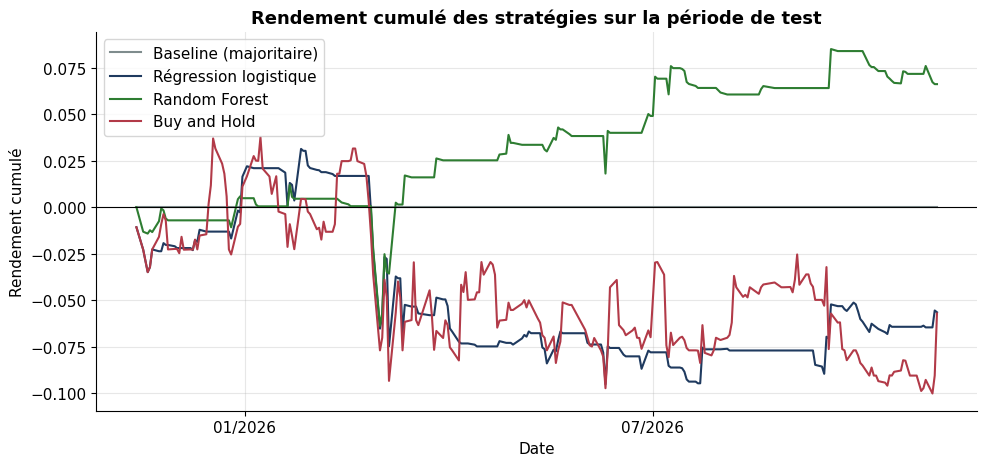

In [21]:
def simuler(pred, rend, cout=COUT):
    pos = pd.Series(np.asarray(pred, dtype=float), index=rend.index)
    chg = (pos - pos.shift(1).fillna(0.0)).abs()                # on part en liquidités
    return pos * rend - chg * cout, int(chg.sum())

def stats_strat(r):
    cum = (1 + r).cumprod()
    return {"Rendement cumulé": cum.iloc[-1] - 1,
            "Sharpe annualisé": np.sqrt(252) * r.mean() / r.std() if r.std() > 0 else np.nan,
            "Drawdown max": (cum / cum.cummax() - 1).min()}

rend_te = pd.Series(test["ret_next"].values, index=test["date"].values)
def buy_hold(cout):
    bh = rend_te.copy(); bh.iloc[0] -= cout; return bh

strats, lignes = {}, []
for nom in res.index:
    strats[nom], nb = simuler(preds[nom], rend_te)
    lignes.append({"Stratégie": nom, "Changements de position": nb, **stats_strat(strats[nom])})
strats["Buy and Hold"] = buy_hold(COUT)
lignes.append({"Stratégie": "Buy and Hold", "Changements de position": 1, **stats_strat(strats["Buy and Hold"])})
sim = pd.DataFrame(lignes).set_index("Stratégie")
print(f"Coût = {COUT*100:.1f} % par changement de position\n", sim.round(4).to_string())
sim.round(4).to_csv(f"{DOSSIER_RES}/resultats_simulation.csv")

sens = pd.DataFrame({f"{c*100:.1f} %": {**{nom: stats_strat(simuler(preds[nom], rend_te, c)[0])["Sharpe annualisé"]
                                          for nom in res.index},
                                       "Buy and Hold": stats_strat(buy_hold(c))["Sharpe annualisé"]}
                     for c in (0.0, 0.001, 0.003)})
print("\nSharpe annualisé selon le coût :\n", sens.round(3).to_string())
sens.round(4).to_csv(f"{DOSSIER_RES}/sensibilite_couts.csv")

fig, ax = plt.subplots(figsize=(10, 4.8))
for (nom, r_s), coul in zip(strats.items(), [GRIS, BLEU, VERT, ROUGE]):
    ax.plot(pd.to_datetime(r_s.index), (1 + r_s).cumprod() - 1, label=nom, color=coul, lw=1.5)
ax.axhline(0, color="black", lw=0.8)
ax.set(title="Rendement cumulé des stratégies sur la période de test", xlabel="Date", ylabel="Rendement cumulé")
axe_dates(ax); ax.legend(); sauver("fig10_strategies.png")

## 11. Conclusion automatique (générée à partir des résultats ci-dessus)

In [22]:
print(f"Sur {len(test)} jours de test, la baseline atteint {acc_base*100:.1f} % d'accuracy.")
for nom in ("Régression logistique", "Random Forest"):
    a, pv = res.loc[nom, "Accuracy"], res.loc[nom, "p-val vs baseline"]
    verdict = "dépasse numériquement la baseline" if a > acc_base else "reste sous la baseline"
    print(f"- {nom} : accuracy {a*100:.1f} %, balanced accuracy {res.loc[nom,'Balanced Acc.']:.3f} -> {verdict} "
          f"(p vs baseline = {pv:.3f}, écart {'significatif' if pv < 0.05 else 'non significatif'} à 5 % ; "
          f"permutation sur la balanced accuracy : p = {res.loc[nom,'p-val permutation (BA)']:.3f}).")
if all(res.loc[m, "p-val vs baseline"] >= 0.05 for m in ("Régression logistique", "Random Forest")):
    print("=> Aucune preuve statistique que ces modèles battent la référence : résultat compatible avec "
          "l'hypothèse de marche aléatoire, sous réserve des limites (une seule période de test, tests non corrigés).")
else:
    print("=> Au moins un modèle dépasse significativement la référence ; à confirmer sur d'autres périodes.")
print(f"- Finance (coût {COUT*100:.1f} %) : meilleur Sharpe = {sim['Sharpe annualisé'].dropna().idxmax()} "
      f"({sim['Sharpe annualisé'].max():.2f}). Sharpe de la baseline non défini (jamais investie).")

json.dump({"n_obs": len(df), "n_modelisation": n, "n_train": len(train), "n_test": len(test),
           "meilleur_C": gs_lr.best_params_, "meilleurs_params_rf": {k: int(v) for k, v in gs_rf.best_params_.items()}},
          open(f"{DOSSIER_RES}/resultats_cles.json", "w"), indent=2, ensure_ascii=False)
print("\nFichiers : figures/*.png et resultats/*.csv")

Sur 238 jours de test, la baseline atteint 58.8 % d'accuracy.
- Régression logistique : accuracy 56.3 %, balanced accuracy 0.535 -> reste sous la baseline (p vs baseline = 0.804, écart non significatif à 5 % ; permutation sur la balanced accuracy : p = 0.162).
- Random Forest : accuracy 59.7 %, balanced accuracy 0.548 -> dépasse numériquement la baseline (p vs baseline = 0.423, écart non significatif à 5 % ; permutation sur la balanced accuracy : p = 0.051).
=> Aucune preuve statistique que ces modèles battent la référence : résultat compatible avec l'hypothèse de marche aléatoire, sous réserve des limites (une seule période de test, tests non corrigés).
- Finance (coût 0.1 %) : meilleur Sharpe = Random Forest (0.75). Sharpe de la baseline non défini (jamais investie).

Fichiers : figures/*.png et resultats/*.csv
